In [6]:
from sklearn.datasets import load_iris

# Load the dataset as a pandas DataFrame
iris = load_iris(as_frame=True)
iris_df = iris.frame

# Separate features (Xc) and target (yc)
Xc = iris_df.drop(columns=["target"])
yc = iris.target

# Preview the features and target class names
print(Xc.head())
print(iris.target_names)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
['setosa' 'versicolor' 'virginica']


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Split data into training (80%) and testing (20%) sets
Xtr, Xte, ytr, yte = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

# Build a pipeline to scale features and train Logistic Regression
log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

# Fit the model and make predictions on the test set
log_model.fit(Xtr, ytr)
pred_log = log_model.predict(Xte)

print(pred_log[:10])


[0 2 1 1 0 1 0 0 2 1]


In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Build a pipeline to scale features and train KNN
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Fit the model and make predictions on the test set
knn.fit(Xtr, ytr)
pred_knn = knn.predict(Xte)

print(pred_knn[:10])

[0 2 1 1 0 1 0 0 2 1]


In [9]:
from sklearn.naive_bayes import GaussianNB

# Initialize and train the Gaussian Naive Bayes model
nb = GaussianNB()
nb.fit(Xtr, ytr)

# Make predictions on the test set
pred_nb = nb.predict(Xte)

print(pred_nb[:10])


[0 2 1 1 0 1 0 0 2 1]


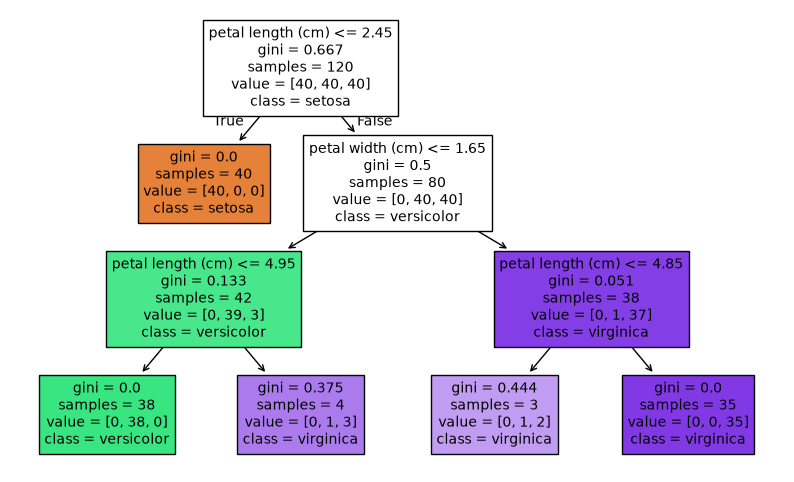

In [10]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Initialize and train the Decision Tree model
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xtr, ytr)

# Make predictions on the test set
pred_tree = tree.predict(Xte)

# Plot the decision tree
plt.figure(figsize=(10, 6))
plot_tree(
    tree,
    feature_names=Xc.columns,
    class_names=iris.target_names,
    filled=True
)
plt.show()


In [11]:
from sklearn.svm import SVC

# Build a pipeline to scale features and train the SVM model
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)

# Fit the model and make predictions on the test set
svm.fit(Xtr, ytr)
pred_svm = svm.predict(Xte)

print(pred_svm[:10])

[0 2 1 1 0 1 0 0 2 1]


In [12]:
from sklearn.metrics import accuracy_score

print("Classes:", iris.target_names)
print("Logistic accuracy:", accuracy_score(yte, pred_log))
print("Tree accuracy:", accuracy_score(yte, pred_tree))


Classes: ['setosa' 'versicolor' 'virginica']
Logistic accuracy: 0.9333333333333333
Tree accuracy: 0.9666666666666667


In [14]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression with balanced class weights
weighted = LogisticRegression(
    class_weight="balanced",
    max_iter=2000
)

print("Balanced class weights enabled")


Balanced class weights enabled


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Initialize Logistic Regression with balanced class weights inside a pipeline
weighted = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000)
)

print("Balanced class weights enabled")

# Fit and evaluate the weighted model
weighted.fit(Xtr, ytr)
pred_weighted = weighted.predict(Xte)
print("Weighted Logistic accuracy:", accuracy_score(yte, pred_weighted))

Balanced class weights enabled
Weighted Logistic accuracy: 0.9333333333333333


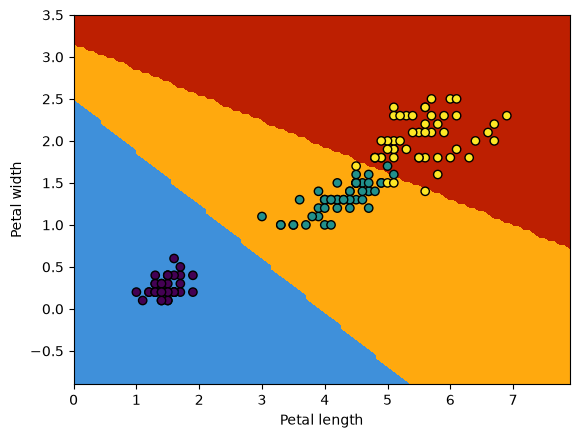

In [17]:
from sklearn.inspection import DecisionBoundaryDisplay

# Select only the two petal features for 2D plotting
X2 = Xc[["petal length (cm)", "petal width (cm)"]]

# Build and fit the model on the 2D feature set
boundary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
boundary_model.fit(X2, yc)

# Plot the decision boundaries and overlay the data points
DecisionBoundaryDisplay.from_estimator(
    boundary_model,
    X2,
    response_method="predict",
    plot_method="contourf"
)
plt.scatter(X2.iloc[:, 0], X2.iloc[:, 1], c=yc, edgecolor="k")
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.show()


In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(yte, pred_log))
print("Precision:", precision_score(yte, pred_log, average="weighted"))
print("Recall:", recall_score(yte, pred_log, average="weighted"))
print("F1:", f1_score(yte, pred_log, average="weighted"))


Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1: 0.9333333333333333


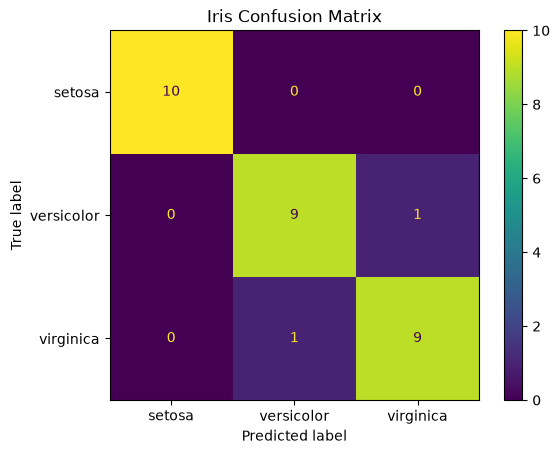

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

# Plot the confusion matrix from true and predicted labels
ConfusionMatrixDisplay.from_predictions(
    yte,
    pred_log,
    display_labels=iris.target_names
)

plt.title("Iris Confusion Matrix")
plt.show()


In [22]:
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic": log_model,
    "KNN": knn,
    "Naive Bayes": nb,
    "Decision Tree": tree,
    "SVM": svm
}

for name, model in models.items():
    pred = model.predict(Xte)
    print(
        name,
        "Accuracy:", round(accuracy_score(yte, pred), 3),
        "F1:", round(f1_score(yte, pred, average="weighted"), 3)
    )


Logistic Accuracy: 0.933 F1: 0.933
KNN Accuracy: 0.933 F1: 0.933
Naive Bayes Accuracy: 0.967 F1: 0.967
Decision Tree Accuracy: 0.967 F1: 0.967
SVM Accuracy: 0.967 F1: 0.967


ROC-AUC: 0.81


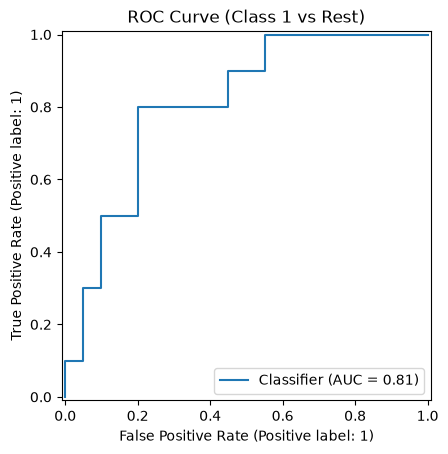

In [23]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import RocCurveDisplay, roc_auc_score

# Convert Iris targets into binary: class 1 (versicolor) vs others (0)
ytr_binary = (ytr == 1).astype(int)
yte_binary = (yte == 1).astype(int)

# Fit a binary classifier that supports predict_proba
binary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)
binary_model.fit(Xtr, ytr_binary)

# Predict probabilities for the positive class (1)
probabilities = binary_model.predict_proba(Xte)[:, 1]

# Print ROC-AUC score and plot the ROC curve
print("ROC-AUC:", round(roc_auc_score(yte_binary, probabilities), 3))

RocCurveDisplay.from_predictions(yte_binary, probabilities)
plt.title("ROC Curve (Class 1 vs Rest)")
plt.show()
